In [1]:
import os
import pathlib


PATH = '/kaggle/input/datasets/mdsifatullahsheikh/grocery-image-classification-104-classes/GroceryMerged'
TEST = str(pathlib.Path(PATH, 'test'))
TRAIN = str(pathlib.Path(PATH, 'train'))
VALID = str(pathlib.Path(PATH, 'val'))

os.listdir(path=PATH)

['README.md',
 'classes.csv',
 'test',
 'test.csv',
 'train',
 'train.csv',
 'val',
 'val.csv']

We want to get image embeddings from ResNeXt for both EDA and classification, so let's add some code to get them.

In [2]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np


DEVICE = torch.device('cpu')
OUTPUT_SIZE = 2048

model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V2)

extraction_layer = model._modules.get('avgpool')
model.to(DEVICE)
model.eval()

scaler = transforms.Resize((224, 224))
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
to_tensor = transforms.ToTensor()

def get_vec(arg, model, extraction_layer):
    image = normalize(to_tensor(scaler(arg))).unsqueeze(0).to(DEVICE)
    result = torch.zeros(1, OUTPUT_SIZE, 1, 1)
    def copy_data(m, i, o):
        result.copy_(o.data)
    hooked = extraction_layer.register_forward_hook(copy_data)
    with torch.no_grad():
        model(image)
    hooked.remove()
    return result

Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 189MB/s]


Let's load up our data. We have a lot of classes, so let's start with a sample, in the interest of time.

In [3]:
import arrow
import base64
import pandas as pd
import tqdm

from glob import iglob
from io import BytesIO
from os.path import basename
from os.path import isdir
from PIL import Image

IGNORE = {}
THUMBNAIL_SIZE = (32, 32)

def embed(model, filename: str):
    try:
        with Image.open(fp=filename, mode='r') as image:
            return get_vec(arg=image.convert('RGB'), model=model, extraction_layer=extraction_layer).numpy().reshape(OUTPUT_SIZE,)
    except: 
        print(filename)
        return None


# https://stackoverflow.com/a/952952
def flatten(arg):
    return [x for xs in arg for x in xs]

def png(filename: str) -> str:
    with Image.open(fp=filename, mode='r') as image:
        buffer = BytesIO()
        # our images are pretty big; let's shrink the hover images to thumbnail size
        image.resize(size=THUMBNAIL_SIZE).convert('RGB').save(buffer, format='png')
        return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()

def get_picture_from_glob(arg: str, tag: str,) -> list:
    result = [pd.Series(data=[tag, basename(input_file), embed(model=model, filename=input_file), png(filename=input_file)],
                        index=['tag', 'name', 'value', 'png'])
        for index, input_file in enumerate(list(iglob(pathname=arg))) if basename(input_file) not in IGNORE]
    return result

time_start = arrow.now()
train_dict = {basename(folder) : folder + '/*.*' for folder in iglob(TRAIN + '/*') if isdir(folder)}
train_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key.replace('-', ' ')) for (key, value) in tqdm.tqdm(desc='train classes', iterable=train_dict.items())]))
test_dict = {basename(folder) : folder + '/*.*' for folder in iglob(TEST + '/*') if isdir(folder)}
test_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key.replace('-', ' ')) for (key, value) in tqdm.tqdm(desc='test classes', iterable=test_dict.items())]))
val_dict = {basename(folder) : folder + '/*.*' for folder in iglob(VALID + '/*') if isdir(folder)}
val_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key.replace('-', ' ')) for (key, value) in tqdm.tqdm(desc='val classes', iterable=val_dict.items())]))
train_df = pd.concat(axis='index', objs=[train_df, val_df])
print('done in {}'.format(arrow.now() - time_start))

val classes: 100%|██████████| 104/104 [06:14<00:00,  3.60s/it]

done in 0:58:03.651155


Let's add x/y coordinates based on our image embeddings using TSNE.

In [4]:
from sklearn.manifold import TSNE

train_reducer = TSNE(random_state=2026, verbose=True, n_jobs=1, perplexity=20.0, init='pca')
train_df[['x', 'y']] = train_reducer.fit_transform(X=train_df['value'].apply(func=pd.Series))
test_reducer = TSNE(random_state=2026, verbose=True, n_jobs=1, perplexity=20.0, init='pca')
test_df[['x', 'y']] = test_reducer.fit_transform(X=test_df['value'].apply(func=pd.Series))

[t-SNE] Computing 61 nearest neighbors...
[t-SNE] Indexed 17953 samples in 0.140s...
[t-SNE] Computed neighbors for 17953 samples in 25.418s...
[t-SNE] Computed conditional probabilities for sample 1000 / 17953
[t-SNE] Computed conditional probabilities for sample 2000 / 17953
[t-SNE] Computed conditional probabilities for sample 3000 / 17953
[t-SNE] Computed conditional probabilities for sample 4000 / 17953
[t-SNE] Computed conditional probabilities for sample 5000 / 17953
[t-SNE] Computed conditional probabilities for sample 6000 / 17953
[t-SNE] Computed conditional probabilities for sample 7000 / 17953
[t-SNE] Computed conditional probabilities for sample 8000 / 17953
[t-SNE] Computed conditional probabilities for sample 9000 / 17953
[t-SNE] Computed conditional probabilities for sample 10000 / 17953
[t-SNE] Computed conditional probabilities for sample 11000 / 17953
[t-SNE] Computed conditional probabilities for sample 12000 / 17953
[t-SNE] Computed conditional probabilities for sa

Let's make an interactive plot.

In [5]:
from bokeh.models import ColumnDataSource
from bokeh.models import HoverTool

from bokeh.plotting import figure
from bokeh.plotting import output_notebook
from bokeh.plotting import show
from bokeh.palettes import Turbo256
from bokeh.transform import factor_cmap

output_notebook()

datasource = ColumnDataSource(train_df[['png', 'tag', 'x', 'y']].sample(n=min(len(train_df) - 1, 10000)))
factor_count = max(train_df['tag'].nunique(), 3)
indices = np.linspace(0, len(Turbo256)-1, factor_count, dtype=int)
palette = [Turbo256[index] for index in indices]
mapper = factor_cmap(field_name = 'tag', palette=palette, factors=train_df['tag'].unique().tolist(), start=0, end=factor_count-1, )

plot_figure = figure(title='TSNE projection: grocery items', width=1000, height=800, tools=('pan, wheel_zoom, reset'))

plot_figure.add_tools(HoverTool(tooltips="""
<div>
    <div>
        <img src='@png' style='float: left; margin: 5px 5px 5px 5px'/>
    </div>
    <div>
        <span style='font-size: 18px'>@tag</span>
    </div>
</div>
"""))

plot_figure.scatter(x='x', y='y', source=datasource, line_alpha=0.6, fill_alpha=0.6, size=8, color=mapper)
show(plot_figure)

Loading BokehJS ...

What do we see? We see a lot of in-class clustering, but also we see some classes clustering together. So some good news, some bad news. Let's make a static plot showing individual thumbnails.

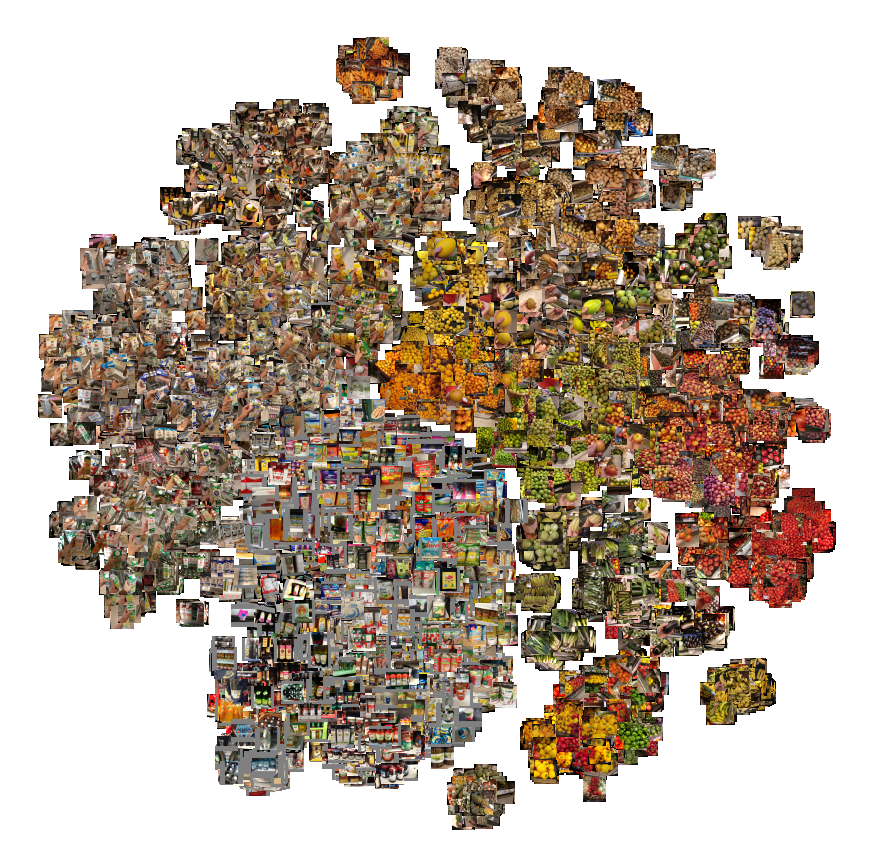

In [6]:
import base64
import io
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image

# we recycled some PNG encoding code above, and we need to postprocess it for using with matplotlib
train_df['PNG'] = train_df['png'].str.replace('^data:image/png;base64,', '', regex=True)

fig, ax = plt.subplots(figsize=(11, 11))

for index, row in train_df.iterrows():
    img_bytes = base64.b64decode(row["PNG"])
    img = Image.open(io.BytesIO(img_bytes))
    imagebox = OffsetImage(img, zoom=0.5)
    ab = AnnotationBbox(imagebox, (row["x"], row["y"]), frameon=False, pad=0)
    ax.add_artist(ab)
ax.scatter(train_df["x"], train_df["y"], alpha=0)
ax.axis('off')
plt.show()

This is kind of neat: the foods with packaging cluster together, and the produce clusters together.

Let's build a model and see what we get.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

logreg = LogisticRegression(max_iter=5000, tol=1e-12, verbose=0, ).fit(train_df['value'].apply(func=pd.Series), train_df['tag'],)
print('model fit in {} iterations'.format(logreg.n_iter_[0]))
print('accuracy: {:5.4f}'.format(accuracy_score(y_true=test_df['tag'], y_pred=logreg.predict(X=test_df['value'].apply(func=pd.Series)))))
print('f1: {:5.4f}'.format(f1_score(average='weighted', y_true=test_df['tag'], y_pred=logreg.predict(X=test_df['value'].apply(func=pd.Series)))))
print(classification_report(zero_division=0.0, y_true=test_df['tag'], y_pred=logreg.predict(X=test_df['value'].apply(func=pd.Series))))

model fit in 2340 iterations
accuracy: 0.8868
f1: 0.8859
                                        precision    recall  f1-score   support

              Alpro Blueberry Soyghurt       1.00      1.00      1.00         6
                  Alpro Fresh Soy Milk       0.75      1.00      0.86         6
                  Alpro Shelf Soy Milk       1.00      0.83      0.91         6
                Alpro Vanilla Soyghurt       1.00      1.00      1.00         5
                                 Anjou       1.00      0.75      0.86         8
       Arla Ecological Medium Fat Milk       1.00      1.00      1.00         6
            Arla Ecological Sour Cream       1.00      1.00      1.00         5
          Arla Lactose Medium Fat Milk       1.00      0.80      0.89         5
                  Arla Medium Fat Milk       1.00      1.00      1.00         7
             Arla Mild Vanilla Yoghurt       1.00      1.00      1.00         6
     Arla Natural Mild Low Fat Yoghurt       1.00      1.00   

We have over 100 classes, and not a lot of instances per class, so an f1 score of 0.8 is pretty good. Let's look at our model probabilities.

<Axes: xlabel='probability', ylabel='Count'>

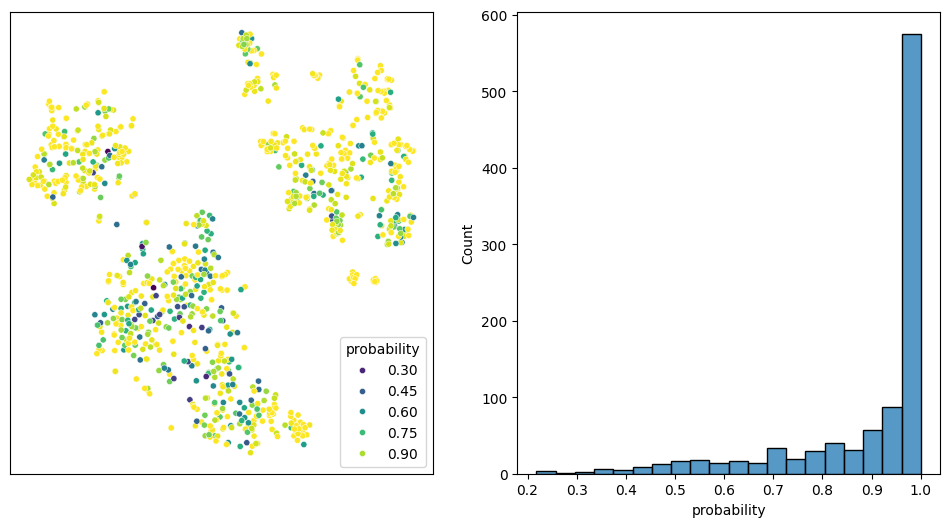

In [8]:
import warnings
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')

plot_df = test_df[['x', 'y']].copy()
plot_df['probability'] = np.max(logreg.predict_proba(X=test_df['value'].apply(func=pd.Series)), axis=1)

fig, ax = plt.subplots(ncols=2, figsize=(12, 6))
sns.scatterplot(ax=ax[0], data=plot_df, x='x', y='y', hue='probability', palette='viridis', s=20)
ax[0].set(xlabel=None)
ax[0].set(ylabel=None)
ax[0].set(xticklabels=[])
ax[0].set(yticklabels=[])
ax[0].tick_params(axis='both', which='both', length=0)
sns.histplot(ax=ax[1], data=plot_df, x='probability', bins=20)

Our model probabilities kind of run the gamut, don't they?